In [ ]:
# PROYECTO BIG DATA: AUTOCINE
# Analisis de datos utilizando Apache Spark y MongoDB Atlas

print("PROYECTO BIG DATA - AUTOCINE")
print("Analisis de datos con Apache Spark y MongoDB Atlas")

In [9]:
# 1. Apache Spark
from pyspark.sql import SparkSession
from pyspark.sql.functions import count, sum

# 2. MongoDB
from pymongo import MongoClient

# 3. Analisis de datos
import pandas as pd

# 4. Graficos
import matplotlib.pyplot as plt

# 5. Archivos JSON
import json

print("Librerias importadas correctamente")

Librerias importadas correctamente


In [10]:
from pymongo import MongoClient
from urllib.parse import quote_plus

# Datos de conexion
usuario = "difertota_db_user"
password = quote_plus("AutoCine2026Fernando123")

URL_MONGO = (
    f"mongodb+srv://{usuario}:{password}"
    "@cluster0.jprrr6g.mongodb.net/"
)

# Conectar con MongoDB Atlas
cliente_mongo = MongoClient(URL_MONGO)

# Seleccionar la base de datos
db = cliente_mongo["autocine_bigdata"]

# Comprobar la conexion
print("Colecciones encontradas:")

print(db.list_collection_names())

Colecciones encontradas:
['entradas', 'peliculas', 'clientes', 'funciones']


In [11]:
# Leer los datos de MongoDB
df_clientes = pd.DataFrame(list(db.clientes.find({}, {"_id": 0})))
df_peliculas = pd.DataFrame(list(db.peliculas.find({}, {"_id": 0})))
df_funciones = pd.DataFrame(list(db.funciones.find({}, {"_id": 0})))
df_entradas = pd.DataFrame(list(db.entradas.find({}, {"_id": 0})))

# Mostrar la cantidad de registros
print("Clientes:", len(df_clientes))
print("Peliculas:", len(df_peliculas))
print("Funciones:", len(df_funciones))
print("Entradas:", len(df_entradas))

# Mostrar una muestra de las entradas
display(df_entradas.head())

Clientes: 10
Peliculas: 10
Funciones: 12
Entradas: 20


,id_entrada,id_cliente,id_funcion,precio
0,5,5,2,35
1,12,2,5,30
2,13,3,6,35
3,16,6,8,35
4,17,7,8,35


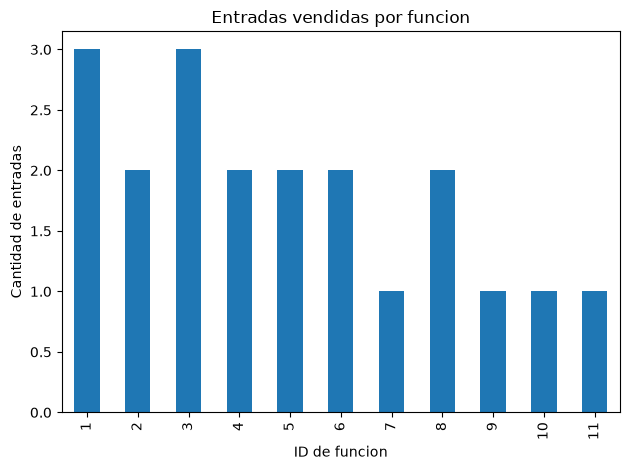

In [12]:
# Contar las entradas vendidas por funcion
ventas_funcion = df_entradas.groupby("id_funcion")["id_entrada"].count()

# Crear el grafico
ventas_funcion.plot(
    kind="bar",
    title="Entradas vendidas por funcion",
    xlabel="ID de funcion",
    ylabel="Cantidad de entradas"
)

plt.tight_layout()
plt.show()

INGRESOS POR FUNCION


,id_funcion,ingreso_total
0,1,105
1,2,70
2,3,105
3,4,70
4,5,60
5,6,70
6,7,35
7,8,70
8,9,30
9,10,40


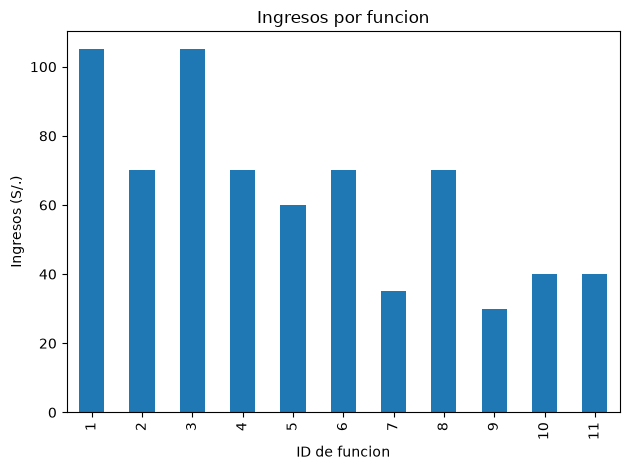

In [13]:
# Calcular los ingresos por funcion
ingresos_funcion = df_entradas.groupby("id_funcion")["precio"].sum()

# Mostrar los resultados
print("INGRESOS POR FUNCION")
display(ingresos_funcion.reset_index(name="ingreso_total"))

# Crear el grafico
ingresos_funcion.plot(
    kind="bar",
    title="Ingresos por funcion",
    xlabel="ID de funcion",
    ylabel="Ingresos (S/.)"
)

plt.tight_layout()
plt.show()


In [14]:
# Analisis de ventas con Apache Spark
# Este codigo se ejecutara en el entorno Spark de Docker.

from pyspark.sql import SparkSession
from pyspark.sql.functions import count, sum

print("Librerias de Spark preparadas para el analisis")

Librerias de Spark preparadas para el analisis


In [ ]:
!docker exec spark-master /opt/spark/bin/spark-submit --packages org.mongodb.spark:mongo-spark-connector_2.12:10.5.0 /opt/spark/work-dir/src/procesar_autocine.py

Ivy Default Cache set to: /root/.ivy2/cache
The jars for the packages stored in: /root/.ivy2/jars
org.mongodb.spark#mongo-spark-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-205f555e-a3a9-4e66-8981-0718f1f43c03;1.0
	confs: [default]
	found org.mongodb.spark#mongo-spark-connector_2.12;10.5.0 in central
	found org.mongodb#mongodb-driver-sync;5.1.4 in central
	[5.1.4] org.mongodb#mongodb-driver-sync;[5.1.1,5.1.99)
	found org.mongodb#bson;5.1.4 in central
	found org.mongodb#mongodb-driver-core;5.1.4 in central
	found org.mongodb#bson-record-codec;5.1.4 in central
:: resolution report :: resolve 1875ms :: artifacts dl 11ms
	:: modules in use:
	org.mongodb#bson;5.1.4 from central in [default]
	org.mongodb#bson-record-codec;5.1.4 from central in [default]
	org.mongodb#mongodb-driver-core;5.1.4 from central in [default]
	org.mongodb#mongodb-driver-sync;5.1.4 from central in [default]
	org.mongodb.spark#mongo-spark-connector_2.12;10.5.0 f

:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml
Spark iniciado correctamente

=== CLIENTES ===
+------------------------+------------------+------------------+---------+
|_id                     |correo            |nombre            |telefono |
+------------------------+------------------+------------------+---------+
|6abe7f2aff42299bf3218384|fernando@gmail.com|Fernando Velasquez|999111111|
|6abe7f54ff42299bf321838e|daniela@gmail.com |Daniela Silva     |999101010|
|6abe7f54ff42299bf321838c|valeria@gmail.com |Valeria Rojas     |999888888|
|6abe7f54ff42299bf3218387|maria@gmail.com   |Maria Lopez       |999333333|
|6abe7f54ff42299bf3218388|andrea@gmail.com  |Andrea Torres     |999444444|
+------------------------+------------------+------------------+---------+
only showing top 5 rows


=== PELICULAS ===
+------------------------+--------+---------------+-----------------------+
|_id                     |duracion|genero   

Ivy Default Cache set to: /root/.ivy2/cache
The jars for the packages stored in: /root/.ivy2/jars
org.mongodb.spark#mongo-spark-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-e030c83a-fe80-48ea-9b7b-33f0ebb0a117;1.0
	confs: [default]
	found org.mongodb.spark#mongo-spark-connector_2.12;10.5.0 in central
	found org.mongodb#mongodb-driver-sync;5.1.4 in central
	[5.1.4] org.mongodb#mongodb-driver-sync;[5.1.1,5.1.99)
	found org.mongodb#bson;5.1.4 in central
	found org.mongodb#mongodb-driver-core;5.1.4 in central
	found org.mongodb#bson-record-codec;5.1.4 in central
:: resolution report :: resolve 1553ms :: artifacts dl 16ms
	:: modules in use:
	org.mongodb#bson;5.1.4 from central in [default]
	org.mongodb#bson-record-codec;5.1.4 from central in [default]
	org.mongodb#mongodb-driver-core;5.1.4 from central in [default]
	org.mongodb#mongodb-driver-sync;5.1.4 from central in [default]
	org.mongodb.spark#mongo-spark-connector_2.12;10.5.0 f

: 